# Planning with crystallography: Bi2Se3 from CIF to detector position

Before an experiment the questions are: which reflections exist, which are
strong, which ones are really the same reflection, how is the crystal
oriented, and where do the circles and the detector have to go? This notebook
answers them for Bi2Se3 (R-3m, hexagonal axes) on the psic six-circle, with
hklforge alone. The reference comparisons (gemmi) run only if it is
installed. Background and what was verified:
[docs/crystallography.md](../docs/crystallography.md).

Needs the extra `hklforge[crystal]` (pandas, xraydb).

In [1]:
import sys, os, logging, warnings
sys.path.insert(0, os.path.abspath("../src"))      # hklforge from this repository
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hklforge import Diffractometer, Geometry, ModeError, Degenerate
from hklforge.lattice import b_matrix
from hklforge.draw import draw, draw_circles
logging.getLogger("diffcalc").setLevel(logging.ERROR)
pd.set_option("display.precision", 3)
%matplotlib inline

In [2]:
from hklforge.crystal import cell, reflections
from hklforge.crystal.spacegroups import SpaceGroup
from hklforge.crystal.structure import read_cif
from hklforge.lattice import angle_between
from hklforge.orient import u_from_two
from hklforge import wavevector

## The structure

`read_cif` takes a path or the CIF text. Bi2Se3 here is the structure in the
test data (hexagonal setting).

In [3]:
st = read_cif("../tests/data/Bi2Se3.cif")
print(st.formula, "|", st.space_group.name, "|", st.cell)
print(f"density {st.density:.3f} g/cm3, {st.z_electrons:.0f} electrons per cell")
print("composition per cell:", st.composition())
print("choices made while reading:", st.notes or "none")
print("cell checks:", cell.check_cell(st.cell, st.space_group) or "consistent")

Bi2Se3 | R -3 m:H | {'a': 4.143, 'b': 4.143, 'c': 28.636, 'alpha': 90.0, 'beta': 90.0, 'gamma': 120.0}
density 7.664 g/cm3, 804 electrons per cell
composition per cell: {'Bi': 6.0, 'Se': 9.0}
choices made while reading: none
cell checks: consistent


## Which reflections exist, and why not

R centring removes two thirds of all reflections. `why_forbidden` names the
reason, which tells you whether an "extra" peak would mean a lower symmetry
(a screw axis or glide that is broken) or just a wrong index.

In [4]:
sg = st.space_group
print("conditions:", sg.condition_summary())
for h in [(0, 0, 1), (0, 0, 3), (1, 0, 0), (0, 1, 5), (1, 0, 4), (0, 0, 6)]:
    print(h, sg.why_forbidden(h) or "allowed", "| mult", sg.multiplicity(h))

conditions: R centring (hexagonal axes, obverse): -h + k + l = 3n
(0, 0, 1) forbidden in R -3 m:H by R centring (hexagonal axes, obverse): -h + k + l = 3n | mult 2
(0, 0, 3) allowed | mult 2
(1, 0, 0) forbidden in R -3 m:H by R centring (hexagonal axes, obverse): -h + k + l = 3n | mult 6
(0, 1, 5) allowed | mult 6
(1, 0, 4) allowed | mult 6
(0, 0, 6) allowed | mult 2


## A reflection list at 9 keV

One row per set of symmetry equivalents, sorted by d, with |F| (f0 + f' + i f''
at the energy, Debye-Waller from the CIF) and the intensity relative to the
strongest, including the multiplicity.

In [5]:
E = 9000
table = reflections.reflection_list(st.cell, E, structure=st, d_min=1.8)
table.head(15)

,h,k,l,d [A],2theta,allowed,why not,mult,|F|,|F|²,I rel
0,0,0,1,28.636,2.757,False,forbidden in R -3 m:H by R centring (hexagonal...,2,4.390e-14,1.927e-27,4.557e-33
1,0,0,2,14.318,5.515,False,forbidden in R -3 m:H by R centring (hexagonal...,2,8.660e-14,7.499e-27,1.773e-32
2,0,0,3,9.545,8.276,True,,2,1.059e+02,1.122e+04,2.654e-02
3,0,0,4,7.159,11.042,False,forbidden in R -3 m:H by R centring (hexagonal...,2,1.531e-13,2.342e-26,5.539e-32
4,0,0,5,5.727,13.815,False,forbidden in R -3 m:H by R centring (hexagonal...,2,3.212e-13,1.032e-25,2.440e-31
5,0,0,6,4.773,16.596,True,,2,2.991e+02,8.948e+04,2.116e-01
6,0,0,7,4.091,19.387,False,forbidden in R -3 m:H by R centring (hexagonal...,2,3.610e-13,1.303e-25,3.082e-31
7,1,0,0,3.588,22.136,False,forbidden in R -3 m:H by R centring (hexagonal...,6,9.132e-14,8.339e-27,1.972e-32
8,0,0,8,3.579,22.189,False,forbidden in R -3 m:H by R centring (hexagonal...,2,1.734e-13,3.006e-26,7.109e-32
9,1,0,1,3.560,22.312,True,,6,2.200e+02,4.840e+04,1.145e-01


The strongest reflections, and what `target_check` says about candidate alignment
reflections (a forbidden one or one that is weak despite being allowed):

In [6]:
display(table.sort_values("I rel", ascending=False).head(8))
for h in [(0, 0, 1), (0, 0, 6), (0, 1, 5), (1, 0, 4)]:
    print(h, reflections.target_check(h, st.cell, structure=st, energy=E) or "fine as a target")

,h,k,l,d [A],2theta,allowed,why not,mult,|F|,|F|²,I rel
19,0,1,5,3.041,26.187,True,,6,650.297,422886.017,1.000
36,1,1,0,2.071,38.843,True,,6,595.358,354451.500,0.838
31,1,0,10,2.238,35.848,True,,6,570.865,325886.838,0.771
45,0,0,15,1.909,42.299,True,,2,500.621,250621.537,0.593
35,0,1,11,2.107,38.161,True,,6,314.668,99015.705,0.234
5,0,0,6,4.773,16.596,True,,2,299.133,89480.538,0.212
46,1,1,6,1.900,42.506,True,,12,250.719,62859.833,0.149
9,1,0,1,3.560,22.312,True,,6,220.007,48403.152,0.114


(0, 0, 1) ['(0 0 1) is forbidden in R -3 m:H by R centring (hexagonal axes, obverse): -h + k + l = 3n']
(0, 0, 6) fine as a target
(0, 1, 5) fine as a target
(1, 0, 4) fine as a target


### Cross-check against gemmi (if installed)

The same |F| from gemmi's calculator. The form-factor tables differ
(Waasmaier-Kirfel here, IT92 in gemmi), so expect agreement to a few 0.1 %. gemmi
uses neutral atoms without anomalous terms, so compare without an energy.

In [7]:
try:
    import gemmi
    small = gemmi.make_small_structure_from_block(gemmi.cif.read_file("../tests/data/Bi2Se3.cif").sole_block())
    small.change_occupancies_to_crystallographic()
    calc = gemmi.StructureFactorCalculatorX(small.cell)
    hkls = [tuple(int(x) for x in r) for r in table[["h", "k", "l"]].values]
    ref = np.array([abs(calc.calculate_sf_from_small_structure(small, list(h))) for h in hkls])
    mine = np.abs(st.structure_factors(hkls))
    strong = ref > 0.05 * ref.max()
    print(f"{strong.sum()} strong reflections: max | |F| / |F_gemmi| - 1 | = {np.max(np.abs(mine[strong] / ref[strong] - 1)):.2%}")
except ImportError:
    print("gemmi not installed - skipped")

17 strong reflections: max | |F| / |F_gemmi| - 1 | = 0.13%


## Anomalous scattering: when F(h) and F(-h) differ

Bi2Se3 is centrosymmetric, so Friedel's law holds at any energy. GaAs is not:
near the Ga K edge (10.367 keV), |F(1 1 1)| and |F(-1 -1 -1)| split - the
signal used to tell the Ga and As faces apart.

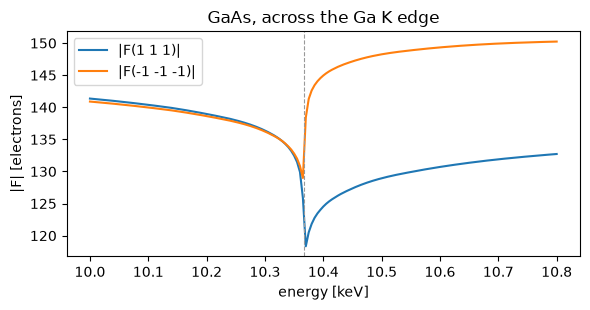

In [8]:
gaas = read_cif("../tests/data/GaAs.cif")
energies = np.linspace(10000, 10800, 161)
F = np.array([np.abs(gaas.structure_factors([(1, 1, 1), (-1, -1, -1)], energy=e)) for e in energies])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(energies / 1e3, F[:, 0], label="|F(1 1 1)|")
ax.plot(energies / 1e3, F[:, 1], label="|F(-1 -1 -1)|")
ax.axvline(10.367, color="0.6", lw=0.8, ls="--")
ax.set_xlabel("energy [keV]"); ax.set_ylabel("|F| [electrons]"); ax.legend(); ax.set_title("GaAs, across the Ga K edge")
plt.tight_layout()

## Equivalent reflections, and reflections an azimuth turn connects

With the c axis along the surface normal, a rotation about the normal (an
azimuth / phi scan) brings some reflections onto each other: same |Q|, same
angle to the axis. `rotation_groups` finds them and the turn needed. This is
not the same as symmetry equivalence: (0 1 5) and (1 0 -5) are equivalent but
lie on opposite sides of the surface plane (Q_par of opposite sign).

The c axis of R-3m is 3-fold, not 6-fold: of the six reflections a 60 deg
turn connects, every second one is forbidden by the R centring, so an azimuth
scan sees (0 1 5)-type peaks every 120 deg.

In [9]:
b = b_matrix(st.cell["a"], st.cell["b"], st.cell["c"], st.cell["alpha"], st.cell["beta"], st.cell["gamma"])
hkls = [(0, 1, 5), (1, 0, -5), (1, -1, 5), (-1, 0, 5), (0, -1, 5), (-1, 1, 5), (1, 0, 4), (0, 1, -4), (0, 0, 6)]
rot = reflections.rotation_groups(hkls, b, b @ [0, 0, 1])
rot.index = [reflections.fmt_hkl(h) for h in hkls]
rot["allowed"] = [sg.is_allowed(h) for h in hkls]
rot.join(reflections.equivalence_groups(hkls, sg).set_index(rot.index)[["family", "mult"]])

,group,|Q|,Q_par,Q_perp,rotation,allowed,family,mult
(0 1 5),0,2.066,1.097,1.751,0.0,True,{0 1 5},6
(1 0 -5),1,2.066,-1.097,1.751,0.0,True,{0 1 5},6
(1 -1 5),0,2.066,1.097,1.751,120.0,True,{0 1 5},6
(-1 0 5),0,2.066,1.097,1.751,-120.0,True,{0 1 5},6
(0 -1 5),0,2.066,1.097,1.751,180.0,False,{1 0 5},6
(-1 1 5),0,2.066,1.097,1.751,-60.0,False,{1 0 5},6
(1 0 4),2,1.959,0.878,1.751,0.0,True,{1 0 4},6
(0 1 -4),3,1.959,-0.878,1.751,0.0,True,{1 0 4},6
(0 0 6),4,1.316,1.316,0.000,NaN,True,{0 0 6},2


## Orientation from two reflections

Say the c axis was found along the surface normal (phi-frame z) and (1 0 0)
along phi-frame x. `u_from_two` gives U (Busing & Levy: the first pair exactly,
the second in the plane it spans with the first).

In [10]:
u = u_from_two(b, (0, 0, 1), (0, 0, 1), (1, 0, 0), (1, 0, 0))
ub = u @ b
print(np.round(u, 6))
print(f"angle between (0 1 5) and (0 0 6): {angle_between(ub, (0, 1, 5), (0, 0, 6)):.3f} deg")

[[ 1. -0.  0.]
 [ 0.  1.  0.]
 [-0. -0.  1.]]
angle between (0 1 5) and (0 0 6): 57.934 deg


## Angles for a reflection, with the incidence held

The strong (0 1 5) with the incidence angle held at 1 deg. psic has six
circles, so three things are held: here mu = nu = 0 and betain. `describe()`
shows how the planner solves it; every solution is returned.

In [11]:
psic = Geometry.builtin("psic")
d = Diffractometer(psic, ub, energy=E, surface_hkl=(0, 0, 1), reference_hkl=(0, 0, 1))
m = {"mu": 0, "nu": 0, "betain": 1}
print(d.plan(m).describe())
sols = d.solve((0, 1, 5), m)
pd.DataFrame([s | {k: d.pseudo(s)[k] for k in ("betain", "betaout", "ttheta")} for s in sols])

psic: mu=0.0, nu=0.0, betain=1.0, detector on h1  [q_x]
  1. Bragg on the detector (delta): b.k' = cos 2theta, projection (<= 2)
  2. beam in the phi frame x = R^T b from Bragg + betain: cone_points (<= 2)
  3. R from (q, x) -> (Q_lab, b); sample (eta, chi, phi): sp3 (<= 2)


,mu,eta,chi,phi,nu,delta,betain,betaout,ttheta
0,0.0,1.848,147.229,-133.304,0.0,26.187,1.0,12.89,26.187
1,0.0,-178.152,-147.229,46.696,0.0,26.187,1.0,12.89,26.187
2,0.0,1.848,32.771,73.304,0.0,26.187,1.0,12.89,26.187
3,0.0,-178.152,-32.771,-106.696,0.0,26.187,1.0,12.89,26.187
4,0.0,178.152,32.771,46.696,0.0,-26.187,1.0,12.89,26.187
5,0.0,-1.848,-32.771,-133.304,0.0,-26.187,1.0,12.89,26.187
6,0.0,178.152,147.229,-106.696,0.0,-26.187,1.0,12.89,26.187
7,0.0,-1.848,-147.229,73.304,0.0,-26.187,1.0,12.89,26.187


## Pointing the detector at a second reflection

At a sample position where a first reflection is in Bragg, a second
reflection h2 is in Bragg too if |k_in + Q2| = |k|. `detector_towards` then
gives the detector circles along k_out = k_in + Q2. Here hklforge's double
diffraction mode (detector on h1) supplies such a position, and the detector
is then moved onto h2 - checked by computing hkl back.

In [12]:
k = wavevector(E)
found = None
for h1, h2 in [((0, 1, 5), (1, 0, 4)), ((0, 1, 5), (0, 0, 6)), ((1, 0, 4), (0, 0, 6)), ((1, 1, 0), (0, 1, 5))]:
    pos = d.solve(h1, {"mu": 0, "nu": 0, "h2": h2})
    if pos:
        found = h1, h2, pos[0]
        break
h1, h2, angles = found
q2 = psic.sample_matrix(angles) @ ub @ np.array(h2, float)
k_out = k * np.asarray(psic.beam) + q2
det = psic.detector_towards(k_out, near=angles)
print("sample position, detector on", h1, {n: round(v, 3) for n, v in angles.items()})
print(f"|k_in + Q2| / |k| = {np.linalg.norm(k_out) / k:.9f}   (1: h2 is in Bragg as well)")
print("detector moved onto", h2, {n: round(v, 3) for n, v in det.items()})
print("hkl at the new detector position:", np.round(d.hkl({**angles, **det}), 9))

sample position, detector on (0, 1, 5) {'mu': 0.0, 'eta': 70.936, 'chi': 94.07, 'phi': -32.555, 'nu': 0.0, 'delta': 26.187}
|k_in + Q2| / |k| = 1.000000000   (1: h2 is in Bragg as well)
detector moved onto (1, 0, 4) {'nu': -20.337, 'delta': 14.505}
hkl at the new detector position: [1. 0. 4.]


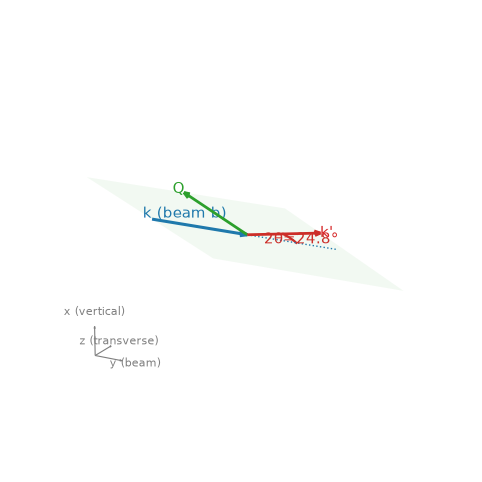

In [13]:
draw(d, {**angles, **det}, show=("ttheta",));